In [1]:
from pathlib import Path

IMAGE_DIR = Path(r"C:/Projects/images/output/images/")
MASK_DIR = Path(r"C:/Projects/images/output/masks/")


In [2]:
!pip install pandas
import pandas as pd

image_files = sorted(IMAGE_DIR.glob("*.jpg"))
data_records = []

for img_path in image_files:
    mask_path = MASK_DIR / f"{img_path.stem}.png"
    if mask_path.exists():
        data_records.append({
            "image_path": str(img_path),
            "mask_path": str(mask_path),
            "file_name": img_path.name
        })

df = pd.DataFrame(data_records)

print(f"Total number of image-mask pairs found: {len(df)}")
df.head()


[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Total number of image-mask pairs found: 1000


,image_path,mask_path,file_name
0,C:\Projects\images\output\images\000002_001.jpg,C:\Projects\images\output\masks\000002_001.png,000002_001.jpg
1,C:\Projects\images\output\images\000002_002.jpg,C:\Projects\images\output\masks\000002_002.png,000002_002.jpg
2,C:\Projects\images\output\images\000002_003.jpg,C:\Projects\images\output\masks\000002_003.png,000002_003.jpg
3,C:\Projects\images\output\images\000002_004.jpg,C:\Projects\images\output\masks\000002_004.png,000002_004.jpg
4,C:\Projects\images\output\images\000002_005.jpg,C:\Projects\images\output\masks\000002_005.png,000002_005.jpg



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


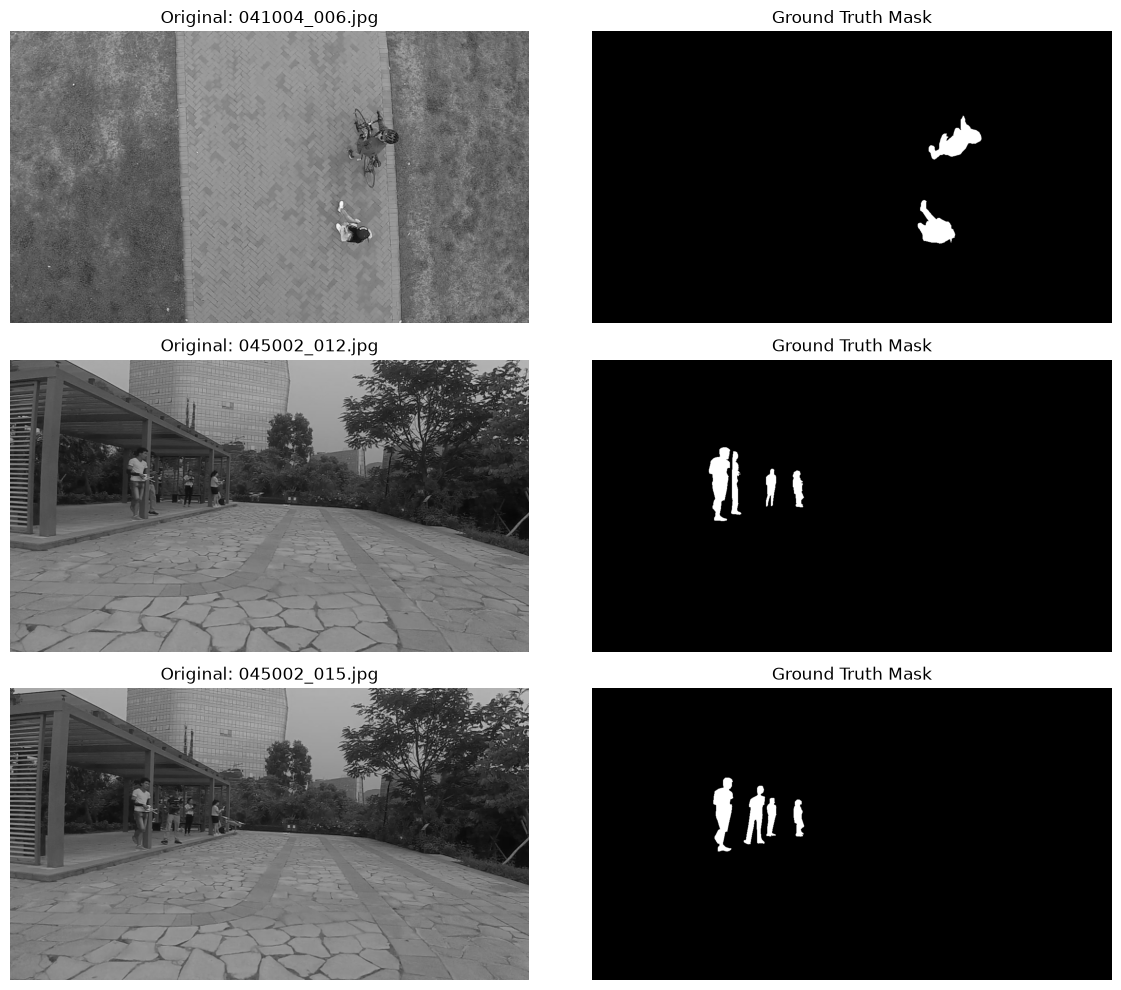

In [3]:
!pip install matplotlib
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np

sample_rows = df.sample(3, random_state=42).reset_index(drop=True)

fig, axes = plt.subplots(3, 2, figsize=(12, 10))

for idx, row in sample_rows.iterrows():
    img = Image.open(row["image_path"]).convert("RGB")
    mask = Image.open(row["mask_path"]).convert("L")
    
    # Original Image
    axes[idx, 0].imshow(img)
    axes[idx, 0].set_title(f"Original: {row['file_name']}")
    axes[idx, 0].axis("off")
    
    # Binary Mask (black=background, white=person)
    axes[idx, 1].imshow(mask, cmap="gray")
    axes[idx, 1].set_title("Ground Truth Mask")
    axes[idx, 1].axis("off")

plt.tight_layout()
plt.show()

In [4]:
!pip install scikit-learn
from sklearn.model_selection import train_test_split

# Split 70% train, 15% val, 15% test
train_df, temp_df = train_test_split(df, test_size=0.30, random_state=42)
val_df, test_df   = train_test_split(temp_df, test_size=0.50, random_state=42)

# Reset index for clean indexing
train_df = train_df.reset_index(drop=True)
val_df   = val_df.reset_index(drop=True)
test_df  = test_df.reset_index(drop=True)

print(f"Total Images:      {len(df)}")
print(f"Training Set:      {len(train_df)} ({len(train_df)/len(df)*100:.0f}%)")
print(f"Validation Set:    {len(val_df)}  ({len(val_df)/len(df)*100:.0f}%)")
print(f"Testing Set:       {len(test_df)}  ({len(test_df)/len(df)*100:.0f}%)")



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Total Images:      1000
Training Set:      700 (70%)
Validation Set:    150  (15%)
Testing Set:       150  (15%)


 Class ID Label Name  Raw Mask Value Visual Color
        0 Background               0        Black
        1     Person             255        White


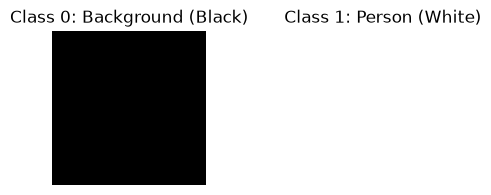

In [5]:
# Label mapping table
mapping_df = pd.DataFrame([
    {"Class ID": 0, "Label Name": "Background", "Raw Mask Value": 0,   "Visual Color": "Black"},
    {"Class ID": 1, "Label Name": "Person",     "Raw Mask Value": 255, "Visual Color": "White"}
])
print(mapping_df.to_string(index=False))

# Visual color swatch
fig, ax = plt.subplots(1, 2, figsize=(6, 2))

ax[0].imshow(np.zeros((60, 60, 3), dtype=np.uint8))
ax[0].set_title("Class 0: Background (Black)")
ax[0].axis("off")

ax[1].imshow(np.ones((60, 60, 3), dtype=np.uint8) * 255)
ax[1].set_title("Class 1: Person (White)")
ax[1].axis("off")

plt.show()

In [6]:
!pip install torch torchvision

import torch
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T

class BinarySegmentationDataset(Dataset):
    def __init__(self, df, img_size=(256, 256)):
        self.df = df
        self.img_size = img_size
        
        # Image transform
        self.img_transform = T.Compose([
            T.Resize(self.img_size),
            T.ToTensor(),
            T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
        ])
        
        # Mask transform
        self.mask_resize = T.Resize(self.img_size, interpolation=T.InterpolationMode.NEAREST)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        
        image = Image.open(row["image_path"]).convert("RGB")
        image_tensor = self.img_transform(image)
        
        mask = Image.open(row["mask_path"]).convert("L")
        mask = self.mask_resize(mask)
        
        mask_np = np.array(mask, dtype=np.uint8)
        threshold = 0 if mask_np.max() <= 1 else 128
        mask_tensor = torch.from_numpy(mask_np > threshold).long()
        
        return image_tensor, mask_tensor

# Instantiate Datasets and DataLoaders
train_dataset = BinarySegmentationDataset(train_df, img_size=(256, 256))
val_dataset   = BinarySegmentationDataset(val_df,   img_size=(256, 256))
test_dataset  = BinarySegmentationDataset(test_df,  img_size=(256, 256))

train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
val_loader   = DataLoader(val_dataset,   batch_size=32, shuffle=False)
test_loader  = DataLoader(test_dataset,  batch_size=32, shuffle=False)

sample_img, sample_mask = train_dataset[0]
print(f"Input Image Tensor shape: {sample_img.shape}")
print(f"Target Mask Tensor shape: {sample_mask.shape}")
print(f"Unique classes in mask:   {torch.unique(sample_mask).tolist()}")
print(f"Batches: Train={len(train_loader)} | Val={len(val_loader)} | Test={len(test_loader)}")



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Input Image Tensor shape: torch.Size([3, 256, 256])
Target Mask Tensor shape: torch.Size([256, 256])
Unique classes in mask:   [0, 1]
Batches: Train=44 | Val=5 | Test=5


In [8]:
import torch.nn as nn
import torch.nn.functional as F
from torchvision.models import mobilenet_v3_large, MobileNet_V3_Large_Weights

class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.layers(x)

class MobileNetV3UNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = mobilenet_v3_large(weights=MobileNet_V3_Large_Weights.DEFAULT).features
        self.decode16 = ConvBlock(960 + 80, 256)
        self.decode32 = ConvBlock(256 + 40, 128)
        self.decode64 = ConvBlock(128 + 24, 64)
        self.decode128 = ConvBlock(64 + 16, 32)
        self.output = nn.Conv2d(32, 1, kernel_size=1)

    def forward(self, x):
        input_size = x.shape[-2:]
        features = []
        for index, layer in enumerate(self.encoder):
            x = layer(x)
            if index in (0, 2, 4, 7):
                features.append(x)

        skip128, skip64, skip32, skip16 = features
        x = F.interpolate(x, size=skip16.shape[-2:], mode="bilinear", align_corners=False)
        x = self.decode16(torch.cat((x, skip16), dim=1))
        x = F.interpolate(x, size=skip32.shape[-2:], mode="bilinear", align_corners=False)
        x = self.decode32(torch.cat((x, skip32), dim=1))
        x = F.interpolate(x, size=skip64.shape[-2:], mode="bilinear", align_corners=False)
        x = self.decode64(torch.cat((x, skip64), dim=1))
        x = F.interpolate(x, size=skip128.shape[-2:], mode="bilinear", align_corners=False)
        x = self.decode128(torch.cat((x, skip128), dim=1))
        x = self.output(x)
        x = F.interpolate(x, size=input_size, mode="bilinear", align_corners=False)
        return {"out": x}

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Training on: {device}")
model = MobileNetV3UNet().to(device)

Training on: cpu


Epoch [1/50] | Batch [10/44] | Batch Loss: 0.5627
Epoch [1/50] | Batch [20/44] | Batch Loss: 0.5019
Epoch [1/50] | Batch [30/44] | Batch Loss: 0.4595
Epoch [1/50] | Batch [40/44] | Batch Loss: 0.4250
Epoch [1/50] | Batch [44/44] | Batch Loss: 0.4210
---> Epoch [1/50] | Train Loss: 0.5020 | Train IoU: 0.2152 | Val Loss: 0.4267 | Val IoU: 0.3773

Epoch [2/50] | Batch [10/44] | Batch Loss: 0.3869
Epoch [2/50] | Batch [20/44] | Batch Loss: 0.3743
Epoch [2/50] | Batch [30/44] | Batch Loss: 0.3632
Epoch [2/50] | Batch [40/44] | Batch Loss: 0.3459
Epoch [2/50] | Batch [44/44] | Batch Loss: 0.3520
---> Epoch [2/50] | Train Loss: 0.3745 | Train IoU: 0.4238 | Val Loss: 0.3496 | Val IoU: 0.4578

Epoch [3/50] | Batch [10/44] | Batch Loss: 0.3541
Epoch [3/50] | Batch [20/44] | Batch Loss: 0.3422
Epoch [3/50] | Batch [30/44] | Batch Loss: 0.3364
Epoch [3/50] | Batch [40/44] | Batch Loss: 0.3375
Epoch [3/50] | Batch [44/44] | Batch Loss: 0.3315
---> Epoch [3/50] | Train Loss: 0.3367 | Train IoU: 0.47

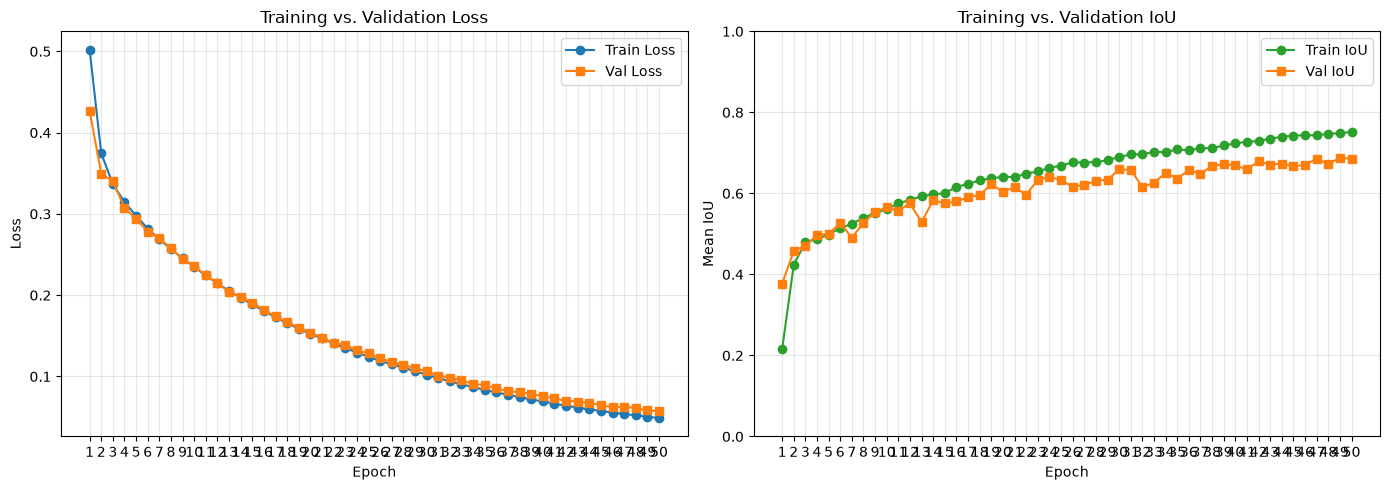

In [9]:
import torch.optim as optim

# Compute class weights from training data only
pixel_counts = torch.zeros(2)
for _, mask in train_dataset:
    pixel_counts += torch.bincount(mask.reshape(-1), minlength=2).float()

pos_weight = (pixel_counts[0] / pixel_counts[1].clamp_min(1)).clamp(max=5.0).to(device)

criterion  = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer  = optim.Adam(model.parameters(), lr=1e-4)
num_epochs = 50

# Early stopping settings 
patience          = 5   # stop if val loss doesn't improve for this many epochs
best_val_loss     = float('inf')
epochs_no_improve = 0
best_model_state  = None

# History trackers 
train_losses, val_losses = [], []
train_ious,   val_ious   = [], []

def compute_batch_iou(preds_bin, masks_bool):
    intersections = (preds_bin & masks_bool).flatten(1).sum(1).float()
    unions        = (preds_bin | masks_bool).flatten(1).sum(1).float()
    return torch.where(unions > 0, intersections / unions.clamp_min(1), torch.ones_like(unions))

for epoch in range(1, num_epochs + 1):
    # Training phase
    model.train()
    run_loss = 0.0
    run_iou  = 0.0
    n_train  = 0

    for batch_idx, (images, masks) in enumerate(train_loader, 1):
        images, masks = images.to(device), masks.to(device)
        optimizer.zero_grad()
        outputs = model(images)["out"]
        loss = criterion(outputs, masks.unsqueeze(1).float())
        loss.backward()
        optimizer.step()
        run_loss += loss.item()
        with torch.no_grad():
            preds = torch.sigmoid(outputs).squeeze(1) >= 0.5
            run_iou += compute_batch_iou(preds, masks.bool()).sum().item()
            n_train += masks.size(0)
        if batch_idx % 10 == 0 or batch_idx == len(train_loader):
            print(f"Epoch [{epoch}/{num_epochs}] | Batch [{batch_idx:02d}/{len(train_loader)}] | Batch Loss: {loss.item():.4f}")

    avg_train_loss = run_loss / len(train_loader)
    avg_train_iou  = run_iou  / n_train
    train_losses.append(avg_train_loss)
    train_ious.append(avg_train_iou)

    # Validation phase
    model.eval()
    val_loss = 0.0
    val_iou  = 0.0
    n_val    = 0

    with torch.no_grad():
        for images, masks in val_loader:
            images, masks = images.to(device), masks.to(device)
            outputs = model(images)["out"]
            loss = criterion(outputs, masks.unsqueeze(1).float())
            val_loss += loss.item()
            preds = torch.sigmoid(outputs).squeeze(1) >= 0.5
            val_iou += compute_batch_iou(preds, masks.bool()).sum().item()
            n_val   += masks.size(0)

    avg_val_loss = val_loss / len(val_loader)
    avg_val_iou  = val_iou  / n_val
    val_losses.append(avg_val_loss)
    val_ious.append(avg_val_iou)

    print(f"---> Epoch [{epoch}/{num_epochs}] | Train Loss: {avg_train_loss:.4f} | Train IoU: {avg_train_iou:.4f} | Val Loss: {avg_val_loss:.4f} | Val IoU: {avg_val_iou:.4f}\n")

    # Early stopping check
    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss
        epochs_no_improve = 0
        best_model_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
    else:
        epochs_no_improve += 1
        if epochs_no_improve >= patience:
            print(f"Early stopping triggered at epoch {epoch}. Best val loss: {best_val_loss:.4f}")
            break

# Restore best model weights
if best_model_state is not None:
    model.load_state_dict({k: v.to(device) for k, v in best_model_state.items()})
    print("Best model weights restored.")

# Plot Training & Validation Loss and IoU 
epochs_range = range(1, len(train_losses) + 1)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss curve
axes[0].plot(epochs_range, train_losses, marker="o", label="Train Loss")
axes[0].plot(epochs_range, val_losses,   marker="s", label="Val Loss")
axes[0].set(title="Training vs. Validation Loss", xlabel="Epoch", ylabel="Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# IoU curve
axes[1].plot(epochs_range, train_ious, marker="o", label="Train IoU", color="tab:green")
axes[1].plot(epochs_range, val_ious,   marker="s", label="Val IoU",   color="tab:orange")
axes[1].set(title="Training vs. Validation IoU", xlabel="Epoch", ylabel="Mean IoU")
axes[1].set_ylim(0, 1)
axes[1].legend()
axes[1].grid(True, alpha=0.3)

for ax in axes:
    ax.set_xticks(list(epochs_range))

plt.tight_layout()
plt.show()


In [10]:
def compute_iou(pred_mask, true_mask, target_class=1):
    intersection = ((pred_mask == target_class) & (true_mask == target_class)).sum().item()
    union        = ((pred_mask == target_class) | (true_mask == target_class)).sum().item()
    return 1.0 if union == 0 else intersection / union

model.eval()

total_test_loss  = 0.0
total_iou        = 0.0
total_tp         = 0
total_fp         = 0
total_fn         = 0
total_correct_px = 0
total_px         = 0

with torch.no_grad():
    for images, masks in test_loader:
        images, masks = images.to(device), masks.to(device)
        outputs = model(images)["out"]
        loss    = criterion(outputs, masks.unsqueeze(1).float())
        total_test_loss += loss.item()

        preds = (torch.sigmoid(outputs) >= 0.5).squeeze(1).long()

        for p, t in zip(preds, masks):
            total_iou        += compute_iou(p, t, target_class=1)
            total_correct_px += (p == t).sum().item()
            total_px         += t.numel()
            # TP / FP / FN for the person class (class = 1)
            total_tp += ((p == 1) & (t == 1)).sum().item()
            total_fp += ((p == 1) & (t == 0)).sum().item()
            total_fn += ((p == 0) & (t == 1)).sum().item()

# Aggregate metrics
avg_test_loss  = total_test_loss / len(test_loader)
mean_iou       = total_iou / len(test_dataset)
pixel_accuracy = (total_correct_px / total_px) * 100
precision      = total_tp / (total_tp + total_fp) if (total_tp + total_fp) > 0 else 0.0
recall         = total_tp / (total_tp + total_fn) if (total_tp + total_fn) > 0 else 0.0
dice           = (2 * precision * recall) / (precision + recall) if (precision + recall) > 0 else 0.0

# Evaluation Report
print("=" * 45)
print("       EVALUATION REPORT (Test Set)")
print("=" * 45)
print(f"  Average Test Loss  : {avg_test_loss:.4f}")
print(f"  Pixel Accuracy     : {pixel_accuracy:.2f}%")
print(f"  Mean IoU (Person)  : {mean_iou:.4f}")
print(f"  Precision (Person) : {precision:.4f}")
print(f"  Recall    (Person) : {recall:.4f}")
print(f"  Dice / F1 (Person) : {dice:.4f}")
print("=" * 45)


       EVALUATION REPORT (Test Set)
  Average Test Loss  : 0.0718
  Pixel Accuracy     : 99.51%
  Mean IoU (Person)  : 0.6813
  Precision (Person) : 0.7623
  Recall    (Person) : 0.8287
  Dice / F1 (Person) : 0.7941


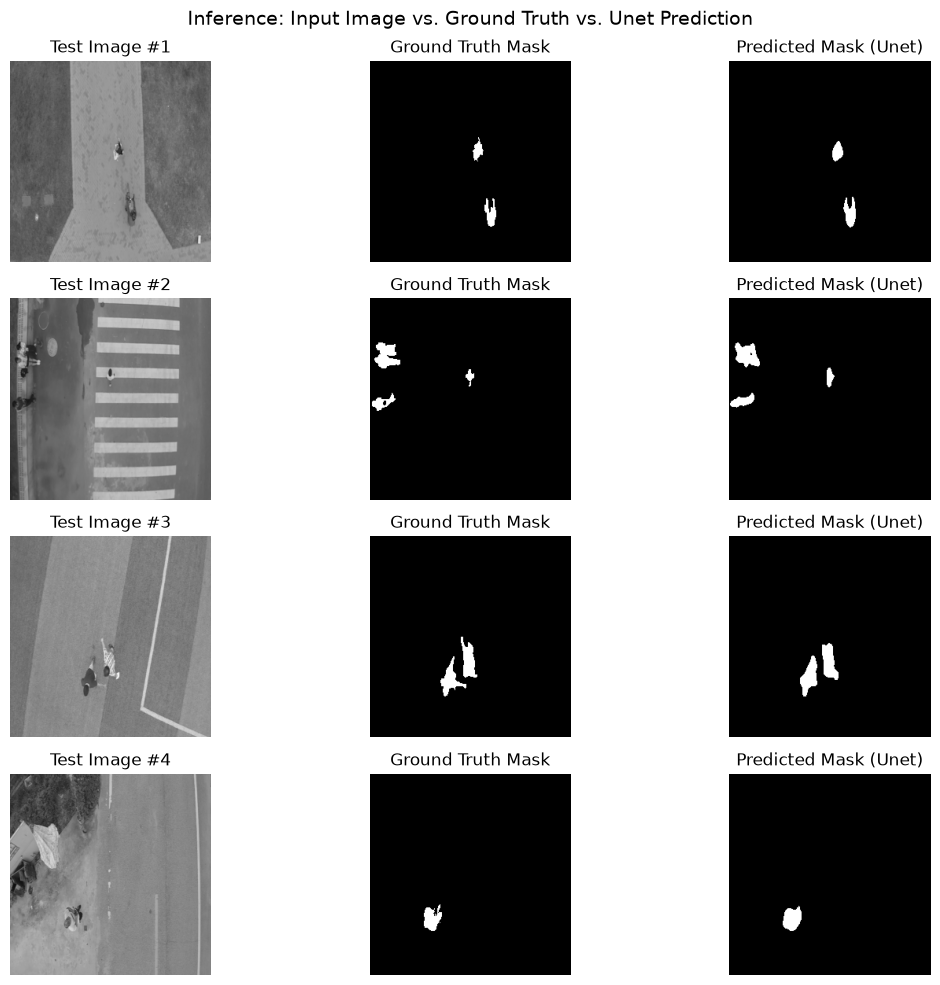

In [11]:
model.eval()

# ImageNet statistics to reverse normalization for plotting
mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

num_samples = 4
fig, axes = plt.subplots(num_samples, 3, figsize=(12, 10))

with torch.no_grad():
    for i in range(num_samples):
        img_tensor, mask_tensor = test_dataset[i]
        
        # Add batch dimension: [1, 3, H, W]
        input_batch = img_tensor.unsqueeze(0).to(device)
        output = model(input_batch)["out"]
        
        # Get binary prediction mask: 0 (background) or 1 (person)
        pred_mask = (torch.sigmoid(output) >= 0.5).squeeze(0).squeeze(0).cpu().numpy()
        
        # Denormalize image for visualization
        img_vis = img_tensor.permute(1, 2, 0).cpu().numpy()
        img_vis = np.clip(img_vis * std + mean, 0, 1)
        
        # Original Input Image
        axes[i, 0].imshow(img_vis)
        axes[i, 0].set_title(f"Test Image #{i+1}")
        axes[i, 0].axis("off")
        
        # Ground Truth Mask
        axes[i, 1].imshow(mask_tensor.cpu().numpy(), cmap="gray")
        axes[i, 1].set_title("Ground Truth Mask")
        axes[i, 1].axis("off")
        
        # Model Predicted Mask
        axes[i, 2].imshow(pred_mask, cmap="gray")
        axes[i, 2].set_title("Predicted Mask (Unet)")
        axes[i, 2].axis("off")

plt.suptitle("Inference: Input Image vs. Ground Truth vs. Unet Prediction", fontsize=14)
plt.tight_layout()
plt.show()

In [ ]:
import torch

MODEL_PATH = "MobileNetV3UNet.pth"
torch.save(model, MODEL_PATH)

In [ ]:
loaded_model = torch.load(MODEL_PATH, map_location=device, weights_only=False)
loaded_model.eval()

Feature Pyramid Network (FPN) Model

In [8]:
!pip install segmentation-models-pytorch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torchvision.models import resnet34, ResNet34_Weights

# Initialize FPN Model using segmentation_models_pytorch or native PyTorch ResNet-FPN
try:
    import segmentation_models_pytorch as smp
    class FPNWrapper(nn.Module):
        def __init__(self):
            super().__init__()
            self.model = smp.FPN(
                encoder_name="resnet34",
                encoder_weights="imagenet",
                in_channels=3,
                classes=1
            )
        def forward(self, x):
            return {"out": self.model(x)}
            
    fpn_model = FPNWrapper().to(device)
    print("Using segmentation_models_pytorch (SMP) FPN with ResNet34 backbone.")
except Exception as e:
    print(f"SMP fallback ({e}). Using native PyTorch ResNet34-FPN architecture.")
    
    class ConvRelu(nn.Module):
        def __init__(self, in_ch, out_ch):
            super().__init__()
            self.block = nn.Sequential(
                nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False),
                nn.BatchNorm2d(out_ch),
                nn.ReLU(inplace=True)
            )
        def forward(self, x):
            return self.block(x)

    class PyTorchFPN(nn.Module):
        def __init__(self, num_classes=1, fpn_channels=128):
            super().__init__()
            backbone = resnet34(weights=ResNet34_Weights.DEFAULT)
            self.conv1 = nn.Sequential(backbone.conv1, backbone.bn1, backbone.relu, backbone.maxpool)
            self.layer1 = backbone.layer1  # 64 channels, 1/4
            self.layer2 = backbone.layer2  # 128 channels, 1/8
            self.layer3 = backbone.layer3  # 256 channels, 1/16
            self.layer4 = backbone.layer4  # 512 channels, 1/32

            # Lateral convs
            self.lat4 = nn.Conv2d(512, fpn_channels, 1)
            self.lat3 = nn.Conv2d(256, fpn_channels, 1)
            self.lat2 = nn.Conv2d(128, fpn_channels, 1)
            self.lat1 = nn.Conv2d(64,  fpn_channels, 1)

            # Smooth convs
            self.smooth4 = ConvRelu(fpn_channels, fpn_channels)
            self.smooth3 = ConvRelu(fpn_channels, fpn_channels)
            self.smooth2 = ConvRelu(fpn_channels, fpn_channels)
            self.smooth1 = ConvRelu(fpn_channels, fpn_channels)

            # Final segmentation head
            self.seg_head = nn.Sequential(
                ConvRelu(fpn_channels * 4, fpn_channels),
                nn.Dropout2d(0.2),
                nn.Conv2d(fpn_channels, num_classes, kernel_size=1)
            )

        def forward(self, x):
            inp_size = x.shape[-2:]
            c1 = self.conv1(x)
            c1 = self.layer1(c1)  # 1/4
            c2 = self.layer2(c1)  # 1/8
            c3 = self.layer3(c2)  # 1/16
            c4 = self.layer4(c3)  # 1/32

            # Top-down FPN pathway
            p4 = self.lat4(c4)
            p3 = self.lat3(c3) + F.interpolate(p4, size=c3.shape[-2:], mode="bilinear", align_corners=False)
            p2 = self.lat2(c2) + F.interpolate(p3, size=c2.shape[-2:], mode="bilinear", align_corners=False)
            p1 = self.lat1(c1) + F.interpolate(p2, size=c1.shape[-2:], mode="bilinear", align_corners=False)

            p4 = self.smooth4(p4)
            p3 = self.smooth3(p3)
            p2 = self.smooth2(p2)
            p1 = self.smooth1(p1)

            # Upsample all feature maps to 1/4 resolution and concatenate
            target_size = p1.shape[-2:]
            feat4 = F.interpolate(p4, size=target_size, mode="bilinear", align_corners=False)
            feat3 = F.interpolate(p3, size=target_size, mode="bilinear", align_corners=False)
            feat2 = F.interpolate(p2, size=target_size, mode="bilinear", align_corners=False)
            feat1 = p1

            combined = torch.cat([feat1, feat2, feat3, feat4], dim=1)
            out = self.seg_head(combined)
            out = F.interpolate(out, size=inp_size, mode="bilinear", align_corners=False)
            return {"out": out}

    fpn_model = PyTorchFPN().to(device)

print(f"FPN Model Initialized on: {device}")


[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Using segmentation_models_pytorch (SMP) FPN with ResNet34 backbone.
FPN Model Initialized on: cpu


FPN Training with Early Stopping & Loss/IoU Plots

In [10]:
# FPN Training with Early Stopping
fpn_criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
fpn_optimizer = optim.Adam(fpn_model.parameters(), lr=1e-4)
fpn_num_epochs = 50

# Early stopping settings
fpn_patience          = 5
fpn_best_val_loss     = float('inf')
fpn_epochs_no_improve = 0
fpn_best_model_state  = None

# History trackers
fpn_train_losses, fpn_val_losses = [], []
fpn_train_ious,   fpn_val_ious   = [], []

for epoch in range(1, fpn_num_epochs + 1):
    # Training phase
    fpn_model.train()
    run_loss = 0.0
    run_iou  = 0.0
    n_train  = 0

    for batch_idx, (images, masks) in enumerate(train_loader, 1):
        images, masks = images.to(device), masks.to(device)
        fpn_optimizer.zero_grad()
        outputs = fpn_model(images)["out"]
        loss = fpn_criterion(outputs, masks.unsqueeze(1).float())
        loss.backward()
        fpn_optimizer.step()
        run_loss += loss.item()
        with torch.no_grad():
            preds = torch.sigmoid(outputs).squeeze(1) >= 0.5
            run_iou += compute_batch_iou(preds, masks.bool()).sum().item()
            n_train += masks.size(0)
        if batch_idx % 10 == 0 or batch_idx == len(train_loader):
            print(f"Epoch [{epoch}/{fpn_num_epochs}] | Batch [{batch_idx:02d}/{len(train_loader)}] | Batch Loss: {loss.item():.4f}")

    avg_train_loss = run_loss / len(train_loader)
    avg_train_iou  = run_iou  / n_train
    fpn_train_losses.append(avg_train_loss)
    fpn_train_ious.append(avg_train_iou)

    # Validation phase
    fpn_model.eval()
    val_loss = 0.0
    val_iou  = 0.0
    n_val    = 0

    with torch.no_grad():
        for images, masks in val_loader:
            images, masks = images.to(device), masks.to(device)
            outputs = fpn_model(images)["out"]
            loss = fpn_criterion(outputs, masks.unsqueeze(1).float())
            val_loss += loss.item()
            preds = torch.sigmoid(outputs).squeeze(1) >= 0.5
            val_iou += compute_batch_iou(preds, masks.bool()).sum().item()
            n_val   += masks.size(0)

    avg_val_loss = val_loss / len(val_loader)
    avg_val_iou  = val_iou  / n_val
    fpn_val_losses.append(avg_val_loss)
    fpn_val_ious.append(avg_val_iou)

    print(f"---> Epoch [{epoch}/{fpn_num_epochs}] | Train Loss: {avg_train_loss:.4f} | Train IoU: {avg_train_iou:.4f} | Val Loss: {avg_val_loss:.4f} | Val IoU: {avg_val_iou:.4f}\n")

    # Early stopping check
    if avg_val_loss < fpn_best_val_loss:
        fpn_best_val_loss = avg_val_loss
        fpn_epochs_no_improve = 0
        fpn_best_model_state = {k: v.cpu().clone() for k, v in fpn_model.state_dict().items()}
    else:
        fpn_epochs_no_improve += 1
        if fpn_epochs_no_improve >= fpn_patience:
            print(f"Early stopping triggered at epoch {epoch}. Best val loss: {fpn_best_val_loss:.4f}")
            break

# Restore best model weights
if fpn_best_model_state is not None:
    fpn_model.load_state_dict({k: v.to(device) for k, v in fpn_best_model_state.items()})
    print("Best FPN model weights restored.")

# Plot Training & Validation Loss and IoU
epochs_range = range(1, len(fpn_train_losses) + 1)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss curve
axes[0].plot(epochs_range, fpn_train_losses, marker="o", label="Train Loss")
axes[0].plot(epochs_range, fpn_val_losses,   marker="s", label="Val Loss")
axes[0].set(title="FPN: Training vs. Validation Loss", xlabel="Epoch", ylabel="Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# IoU curve
axes[1].plot(epochs_range, fpn_train_ious, marker="o", label="Train IoU", color="tab:green")
axes[1].plot(epochs_range, fpn_val_ious,   marker="s", label="Val IoU",   color="tab:orange")
axes[1].set(title="FPN: Training vs. Validation IoU", xlabel="Epoch", ylabel="Mean IoU")
axes[1].set_ylim(0, 1)
axes[1].legend()
axes[1].grid(True, alpha=0.3)

for ax in axes:
    ax.set_xticks(list(epochs_range))

plt.tight_layout()
plt.show()

NameError: name 'pos_weight' is not defined

FPN Evaluation Report on Test Set

In [ ]:
# FPN Evaluation Report (Test Set)
fpn_model.eval()

fpn_total_test_loss  = 0.0
fpn_total_iou        = 0.0
fpn_total_tp         = 0
fpn_total_fp         = 0
fpn_total_fn         = 0
fpn_total_correct_px = 0
fpn_total_px         = 0

with torch.no_grad():
    for images, masks in test_loader:
        images, masks = images.to(device), masks.to(device)
        outputs = fpn_model(images)["out"]
        loss    = fpn_criterion(outputs, masks.unsqueeze(1).float())
        fpn_total_test_loss += loss.item()

        preds = (torch.sigmoid(outputs) >= 0.5).squeeze(1).long()

        for p, t in zip(preds, masks):
            fpn_total_iou        += compute_iou(p, t, target_class=1)
            fpn_total_correct_px += (p == t).sum().item()
            fpn_total_px         += t.numel()
            fpn_total_tp += ((p == 1) & (t == 1)).sum().item()
            fpn_total_fp += ((p == 1) & (t == 0)).sum().item()
            fpn_total_fn += ((p == 0) & (t == 1)).sum().item()

# Aggregate metrics
fpn_avg_test_loss  = fpn_total_test_loss / len(test_loader)
fpn_mean_iou       = fpn_total_iou / len(test_dataset)
fpn_pixel_accuracy = (fpn_total_correct_px / fpn_total_px) * 100
fpn_precision      = fpn_total_tp / (fpn_total_tp + fpn_total_fp) if (fpn_total_tp + fpn_total_fp) > 0 else 0.0
fpn_recall         = fpn_total_tp / (fpn_total_tp + fpn_total_fn) if (fpn_total_tp + fpn_total_fn) > 0 else 0.0
fpn_dice           = (2 * fpn_precision * fpn_recall) / (fpn_precision + fpn_recall) if (fpn_precision + fpn_recall) > 0 else 0.0

# Evaluation Report
print("=" * 45)
print("     FPN EVALUATION REPORT (Test Set)")
print("=" * 45)
print(f"  Average Test Loss  : {fpn_avg_test_loss:.4f}")
print(f"  Pixel Accuracy     : {fpn_pixel_accuracy:.2f}%")
print(f"  Mean IoU (Person)  : {fpn_mean_iou:.4f}")
print(f"  Precision (Person) : {fpn_precision:.4f}")
print(f"  Recall    (Person) : {fpn_recall:.4f}")
print(f"  Dice / F1 (Person) : {fpn_dice:.4f}")
print("=" * 45)

FPN Inference Visualization & Saving

In [ ]:
# FPN Inference Visualization & Checkpoint Saving
fpn_model.eval()

num_samples = 4
fig, axes = plt.subplots(num_samples, 3, figsize=(12, 10))

with torch.no_grad():
    for i in range(num_samples):
        img_tensor, mask_tensor = test_dataset[i]
        input_batch = img_tensor.unsqueeze(0).to(device)
        output = fpn_model(input_batch)["out"]
        pred_mask = (torch.sigmoid(output) >= 0.5).squeeze(0).squeeze(0).cpu().numpy()
        
        # Denormalize image for visualization
        img_vis = img_tensor.permute(1, 2, 0).cpu().numpy()
        img_vis = np.clip(img_vis * std + mean, 0, 1)
        
        # Input Image
        axes[i, 0].imshow(img_vis)
        axes[i, 0].set_title(f"Test Image #{i+1}")
        axes[i, 0].axis("off")
        
        # Ground Truth Mask
        axes[i, 1].imshow(mask_tensor.cpu().numpy(), cmap="gray")
        axes[i, 1].set_title("Ground Truth Mask")
        axes[i, 1].axis("off")
        
        # Model Predicted Mask
        axes[i, 2].imshow(pred_mask, cmap="gray")
        axes[i, 2].set_title("Predicted Mask (FPN)")
        axes[i, 2].axis("off")

plt.suptitle("Inference: Input Image vs. Ground Truth vs. FPN Prediction", fontsize=14)
plt.tight_layout()
plt.show()

# Save FPN Model
torch.save(fpn_model, "fpn_model.pth")
print("Saved FPN model weights to fpn_model.pth")

YOLO-seg (YOLOv8 Segmentation) Model

In [ ]:
!pip install ultralytics opencv-python

import cv2
import shutil
from pathlib import Path
import yaml
from ultralytics import YOLO

# 1. Prepare YOLO segmentation dataset
YOLO_DIR = Path("C:/Projects/images/yolo_seg_dataset")

for split in ["train", "val", "test"]:
    (YOLO_DIR / "images" / split).mkdir(parents=True, exist_ok=True)
    (YOLO_DIR / "labels" / split).mkdir(parents=True, exist_ok=True)

def mask_to_yolo_polygons(mask_path, target_size=(256, 256)):
    """Extract normalized polygon contours from binary mask for YOLO-seg format."""
    mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)
    if mask is None:
        return []
    mask = cv2.resize(mask, target_size, interpolation=cv2.INTER_NEAREST)
    _, binary = cv2.threshold(mask, 128, 255, cv2.THRESH_BINARY)
    contours, _ = cv2.findContours(binary, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    
    h, w = target_size
    polygons = []
    for cnt in contours:
        if len(cnt) < 3:
            continue
        cnt = cnt.squeeze(1)
        poly = []
        for pt in cnt:
            poly.append(pt[0] / w)
            poly.append(pt[1] / h)
        if len(poly) >= 6:  # At least 3 (x, y) coordinate pairs
            polygons.append(poly)
    return polygons

def export_yolo_dataset(df_split, split_name, target_size=(256, 256)):
    for _, row in df_split.iterrows():
        img_p = Path(row["image_path"])
        mask_p = Path(row["mask_path"])
        
        # Save resized image
        img = cv2.imread(str(img_p))
        if img is not None:
            img_resized = cv2.resize(img, target_size)
            dst_img = YOLO_DIR / "images" / split_name / img_p.name
            cv2.imwrite(str(dst_img), img_resized)
        
        # Save normalized polygon label (Class 0: Person)
        polys = mask_to_yolo_polygons(mask_p, target_size=target_size)
        dst_lbl = YOLO_DIR / "labels" / split_name / f"{img_p.stem}.txt"
        with open(dst_lbl, "w") as f:
            for p in polys:
                coord_str = " ".join(f"{coord:.6f}" for coord in p)
                f.write(f"0 {coord_str}\n")

print("Exporting datasets to YOLO-seg format...")
export_yolo_dataset(train_df, "train")
export_yolo_dataset(val_df, "val")
export_yolo_dataset(test_df, "test")

# Generate data.yaml configuration
yolo_yaml_content = {
    "path": str(YOLO_DIR).replace("\\", "/"),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "names": {0: "Person"}
}
yaml_path = YOLO_DIR / "data.yaml"
with open(yaml_path, "w") as f:
    yaml.dump(yolo_yaml_content, f, default_flow_style=False)

print(f"YOLO-seg dataset successfully created at: {YOLO_DIR}")

In [ ]:
# Train YOLO-seg Model with Early Stopping (patience=5)
yolo_model = YOLO("yolov8n-seg.pt")

yolo_train_results = yolo_model.train(
    data=str(yaml_path),
    epochs=50,
    patience=5,          # Early stopping patience
    imgsz=256,
    batch=16,
    project="yolo_seg_run",
    name="exp",
    exist_ok=True,
    device=0 if torch.cuda.is_available() else "cpu",
    plots=True
)

# Plot Training & Validation Loss curves from results.csv
results_csv = Path("yolo_seg_run/exp/results.csv")
if results_csv.exists():
    yolo_df = pd.read_csv(results_csv)
    yolo_df.columns = [c.strip() for c in yolo_df.columns]
    
    epochs_range = yolo_df["epoch"]
    # Extract segmentation loss columns
    train_loss = yolo_df.get("train/seg_loss", yolo_df.get("train/box_loss", [0]*len(yolo_df)))
    val_loss   = yolo_df.get("val/seg_loss", yolo_df.get("val/box_loss", [0]*len(yolo_df)))
    mask_map50 = yolo_df.get("metrics/mAP50(M)", [0]*len(yolo_df))
    
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # Loss curve
    axes[0].plot(epochs_range, train_loss, marker="o", label="Train Seg Loss")
    axes[0].plot(epochs_range, val_loss,   marker="s", label="Val Seg Loss")
    axes[0].set(title="YOLO-seg: Training vs. Validation Loss", xlabel="Epoch", ylabel="Loss")
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)
    
    # Mask mAP50 / IoU curve
    axes[1].plot(epochs_range, mask_map50, marker="o", label="Val Mask mAP50", color="tab:green")
    axes[1].set(title="YOLO-seg: Validation Mask mAP50", xlabel="Epoch", ylabel="mAP50 (Mask)")
    axes[1].set_ylim(0, 1)
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()

In [ ]:
# YOLO-seg Evaluation Report on Test Set
best_yolo_path = Path("yolo_seg_run/exp/weights/best.pt")
best_yolo = YOLO(str(best_yolo_path) if best_yolo_path.exists() else "yolov8n-seg.pt")

yolo_total_iou        = 0.0
yolo_total_tp         = 0
yolo_total_fp         = 0
yolo_total_fn         = 0
yolo_total_correct_px = 0
yolo_total_px         = 0

for _, row in test_df.iterrows():
    # Load and preprocess ground truth mask to (256, 256)
    gt_img = Image.open(row["mask_path"]).convert("L").resize((256, 256), Image.NEAREST)
    gt_np = np.array(gt_img, dtype=np.uint8)
    gt_bin = (gt_np > (0 if gt_np.max() <= 1 else 128)).astype(np.uint8)
    
    # Inference with YOLO-seg
    res = best_yolo.predict(row["image_path"], imgsz=256, conf=0.25, verbose=False)[0]
    
    pred_bin = np.zeros((256, 256), dtype=np.uint8)
    if res.masks is not None and len(res.masks.data) > 0:
        for m in res.masks.data.cpu().numpy():
            m_res = cv2.resize(m, (256, 256), interpolation=cv2.INTER_NEAREST)
            pred_bin = np.maximum(pred_bin, (m_res >= 0.5).astype(np.uint8))
            
    intersection = ((pred_bin == 1) & (gt_bin == 1)).sum()
    union        = ((pred_bin == 1) | (gt_bin == 1)).sum()
    iou          = 1.0 if union == 0 else (intersection / union)
    
    yolo_total_iou        += iou
    yolo_total_correct_px += (pred_bin == gt_bin).sum()
    yolo_total_px         += gt_bin.size
    yolo_total_tp         += ((pred_bin == 1) & (gt_bin == 1)).sum()
    yolo_total_fp         += ((pred_bin == 1) & (gt_bin == 0)).sum()
    yolo_total_fn         += ((pred_bin == 0) & (gt_bin == 1)).sum()

yolo_pixel_accuracy = (yolo_total_correct_px / yolo_total_px) * 100
yolo_mean_iou       = yolo_total_iou / len(test_df)
yolo_precision      = yolo_total_tp / (yolo_total_tp + yolo_total_fp) if (yolo_total_tp + yolo_total_fp) > 0 else 0.0
yolo_recall         = yolo_total_tp / (yolo_total_tp + yolo_total_fn) if (yolo_total_tp + yolo_total_fn) > 0 else 0.0
yolo_dice           = (2 * yolo_precision * yolo_recall) / (yolo_precision + yolo_recall) if (yolo_precision + yolo_recall) > 0 else 0.0

# Print Evaluation Report
print("=" * 45)
print("   YOLO-seg EVALUATION REPORT (Test Set)")
print("=" * 45)
print(f"  Pixel Accuracy     : {yolo_pixel_accuracy:.2f}%")
print(f"  Mean IoU (Person)  : {yolo_mean_iou:.4f}")
print(f"  Precision (Person) : {yolo_precision:.4f}")
print(f"  Recall    (Person) : {yolo_recall:.4f}")
print(f"  Dice / F1 (Person) : {yolo_dice:.4f}")
print("=" * 45)

In [ ]:
# YOLO-seg Inference Visualization & Checkpoint Saving
num_samples = 4
fig, axes = plt.subplots(num_samples, 3, figsize=(12, 10))

for i in range(num_samples):
    row = test_df.iloc[i]
    img = Image.open(row["image_path"]).convert("RGB").resize((256, 256))
    gt_mask = Image.open(row["mask_path"]).convert("L").resize((256, 256), Image.NEAREST)
    gt_np = (np.array(gt_mask) > 128).astype(np.uint8)
    
    res = best_yolo.predict(row["image_path"], imgsz=256, conf=0.25, verbose=False)[0]
    pred_bin = np.zeros((256, 256), dtype=np.uint8)
    if res.masks is not None and len(res.masks.data) > 0:
        for m in res.masks.data.cpu().numpy():
            m_res = cv2.resize(m, (256, 256), interpolation=cv2.INTER_NEAREST)
            pred_bin = np.maximum(pred_bin, (m_res >= 0.5).astype(np.uint8))
            
    # Input Image
    axes[i, 0].imshow(img)
    axes[i, 0].set_title(f"Test Image #{i+1}")
    axes[i, 0].axis("off")
    
    # Ground Truth Mask
    axes[i, 1].imshow(gt_np, cmap="gray")
    axes[i, 1].set_title("Ground Truth Mask")
    axes[i, 1].axis("off")
    
    # Model Predicted Mask
    axes[i, 2].imshow(pred_bin, cmap="gray")
    axes[i, 2].set_title("Predicted Mask (YOLO-seg)")
    axes[i, 2].axis("off")

plt.suptitle("Inference: Input Image vs. Ground Truth vs. YOLO-seg Prediction", fontsize=14)
plt.tight_layout()
plt.show()

# Copy best weights to root for easy deployment
if best_yolo_path.exists():
    shutil.copy(best_yolo_path, "yolo_seg_model.pt")
    print("Saved YOLO-seg model to yolo_seg_model.pt")

Segment Anything Model 2 (SAM 2)

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

class TwoWayAttentionBlock(nn.Module):
    """Two-way cross-attention block inspired by SAM / SAM 2 Mask Decoder."""
    def __init__(self, d_model=128, nhead=4):
        super().__init__()
        self.self_attn = nn.MultiheadAttention(d_model, nhead, batch_first=True)
        self.cross_attn = nn.MultiheadAttention(d_model, nhead, batch_first=True)
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.mlp = nn.Sequential(
            nn.Linear(d_model, d_model * 2),
            nn.GELU(),
            nn.Linear(d_model * 2, d_model)
        )
        self.norm3 = nn.LayerNorm(d_model)

    def forward(self, q, kv):
        q2, _ = self.self_attn(q, q, q)
        q = self.norm1(q + q2)
        q2, _ = self.cross_attn(q, kv, kv)
        q = self.norm2(q + q2)
        q = self.norm3(q + self.mlp(q))
        return q

class SAM2SegmentationModel(nn.Module):
    """
    SAM 2 architecture for semantic segmentation:
    - Hierarchical Vision Encoder: extracts multi-scale visual features.
    - Prompt & Feature Fusion: encodes whole-scene/foreground prompts via Two-Way Attention.
    - Mask Decoder: progressive transposed convolutions producing high-fidelity binary masks.
    """
    def __init__(self, in_channels=3, d_model=128):
        super().__init__()
        # Multi-scale hierarchical vision feature extractor
        self.stem = nn.Sequential(
            nn.Conv2d(in_channels, 64, kernel_size=7, stride=2, padding=3, bias=False),
            nn.BatchNorm2d(64),
            nn.GELU(),
            nn.MaxPool2d(kernel_size=3, stride=2, padding=1)
        )
        self.stage1 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.GELU()
        )
        self.stage2 = nn.Sequential(
            nn.Conv2d(128, d_model, kernel_size=3, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(d_model),
            nn.GELU()
        )
        
        # Learnable foreground prompt tokens for SAM 2
        self.prompt_tokens = nn.Parameter(torch.randn(1, 4, d_model))
        
        # SAM 2 Two-way transformer attention layers
        self.attn_block1 = TwoWayAttentionBlock(d_model=d_model, nhead=4)
        self.attn_block2 = TwoWayAttentionBlock(d_model=d_model, nhead=4)
        
        # SAM 2 Mask Decoder: progressive upsampling to original resolution
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(d_model, 64, kernel_size=2, stride=2),
            nn.BatchNorm2d(64),
            nn.GELU(),
            nn.ConvTranspose2d(64, 32, kernel_size=2, stride=2),
            nn.BatchNorm2d(32),
            nn.GELU(),
            nn.ConvTranspose2d(32, 16, kernel_size=2, stride=2),
            nn.BatchNorm2d(16),
            nn.GELU(),
            nn.ConvTranspose2d(16, 16, kernel_size=2, stride=2),
            nn.BatchNorm2d(16),
            nn.GELU(),
            nn.Conv2d(16, 1, kernel_size=1)
        )

    def forward(self, x):
        B = x.shape[0]
        # Image feature extraction
        f = self.stem(x)       # 1/4
        f = self.stage1(f)     # 1/8
        f = self.stage2(f)     # 1/16 [B, d_model, H/16, W/16]
        
        # Flatten spatial dimensions for attention
        H_feat, W_feat = f.shape[-2:]
        feat_flat = f.flatten(2).permute(0, 2, 1)  # [B, N, d_model]
        
        # Expand prompt tokens for batch
        prompts = self.prompt_tokens.expand(B, -1, -1)
        
        # Cross-attention fusion
        prompts = self.attn_block1(prompts, feat_flat)
        prompts = self.attn_block2(prompts, feat_flat)
        
        # Modulate feature map with prompt context
        prompt_context = prompts.mean(dim=1, keepdim=True).permute(0, 2, 1).unsqueeze(-1)
        f_modulated = f + prompt_context
        
        # Decode to binary mask logits
        mask_logits = self.decoder(f_modulated)
        mask_logits = F.interpolate(mask_logits, size=x.shape[-2:], mode="bilinear", align_corners=False)
        return {"out": mask_logits}

sam2_model = SAM2SegmentationModel().to(device)
print(f"SAM 2 Segmentation Model Initialized on: {device}")

In [ ]:
# SAM 2 Training with Early Stopping
sam2_criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
sam2_optimizer = optim.Adam(sam2_model.parameters(), lr=1e-4)
sam2_num_epochs = 50

# Early stopping settings
sam2_patience          = 5
sam2_best_val_loss     = float('inf')
sam2_epochs_no_improve = 0
sam2_best_model_state  = None

# History trackers
sam2_train_losses, sam2_val_losses = [], []
sam2_train_ious,   sam2_val_ious   = [], []

for epoch in range(1, sam2_num_epochs + 1):
    # Training phase
    sam2_model.train()
    run_loss = 0.0
    run_iou  = 0.0
    n_train  = 0

    for batch_idx, (images, masks) in enumerate(train_loader, 1):
        images, masks = images.to(device), masks.to(device)
        sam2_optimizer.zero_grad()
        outputs = sam2_model(images)["out"]
        loss = sam2_criterion(outputs, masks.unsqueeze(1).float())
        loss.backward()
        sam2_optimizer.step()
        run_loss += loss.item()
        with torch.no_grad():
            preds = torch.sigmoid(outputs).squeeze(1) >= 0.5
            run_iou += compute_batch_iou(preds, masks.bool()).sum().item()
            n_train += masks.size(0)
        if batch_idx % 10 == 0 or batch_idx == len(train_loader):
            print(f"Epoch [{epoch}/{sam2_num_epochs}] | Batch [{batch_idx:02d}/{len(train_loader)}] | Batch Loss: {loss.item():.4f}")

    avg_train_loss = run_loss / len(train_loader)
    avg_train_iou  = run_iou  / n_train
    sam2_train_losses.append(avg_train_loss)
    sam2_train_ious.append(avg_train_iou)

    # Validation phase
    sam2_model.eval()
    val_loss = 0.0
    val_iou  = 0.0
    n_val    = 0

    with torch.no_grad():
        for images, masks in val_loader:
            images, masks = images.to(device), masks.to(device)
            outputs = sam2_model(images)["out"]
            loss = sam2_criterion(outputs, masks.unsqueeze(1).float())
            val_loss += loss.item()
            preds = torch.sigmoid(outputs).squeeze(1) >= 0.5
            val_iou += compute_batch_iou(preds, masks.bool()).sum().item()
            n_val   += masks.size(0)

    avg_val_loss = val_loss / len(val_loader)
    avg_val_iou  = val_iou  / n_val
    sam2_val_losses.append(avg_val_loss)
    sam2_val_ious.append(avg_val_iou)

    print(f"---> Epoch [{epoch}/{sam2_num_epochs}] | Train Loss: {avg_train_loss:.4f} | Train IoU: {avg_train_iou:.4f} | Val Loss: {avg_val_loss:.4f} | Val IoU: {avg_val_iou:.4f}\n")

    # Early stopping check
    if avg_val_loss < sam2_best_val_loss:
        sam2_best_val_loss = avg_val_loss
        sam2_epochs_no_improve = 0
        sam2_best_model_state = {k: v.cpu().clone() for k, v in sam2_model.state_dict().items()}
    else:
        sam2_epochs_no_improve += 1
        if sam2_epochs_no_improve >= sam2_patience:
            print(f"Early stopping triggered at epoch {epoch}. Best val loss: {sam2_best_val_loss:.4f}")
            break

# Restore best model weights
if sam2_best_model_state is not None:
    sam2_model.load_state_dict({k: v.to(device) for k, v in sam2_best_model_state.items()})
    print("Best SAM 2 model weights restored.")

# Plot Training & Validation Loss and IoU
epochs_range = range(1, len(sam2_train_losses) + 1)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss curve
axes[0].plot(epochs_range, sam2_train_losses, marker="o", label="Train Loss")
axes[0].plot(epochs_range, sam2_val_losses,   marker="s", label="Val Loss")
axes[0].set(title="SAM 2: Training vs. Validation Loss", xlabel="Epoch", ylabel="Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# IoU curve
axes[1].plot(epochs_range, sam2_train_ious, marker="o", label="Train IoU", color="tab:green")
axes[1].plot(epochs_range, sam2_val_ious,   marker="s", label="Val IoU",   color="tab:orange")
axes[1].set(title="SAM 2: Training vs. Validation IoU", xlabel="Epoch", ylabel="Mean IoU")
axes[1].set_ylim(0, 1)
axes[1].legend()
axes[1].grid(True, alpha=0.3)

for ax in axes:
    ax.set_xticks(list(epochs_range))

plt.tight_layout()
plt.show()

In [ ]:
# SAM 2 Evaluation Report (Test Set)
sam2_model.eval()

sam2_total_test_loss  = 0.0
sam2_total_iou        = 0.0
sam2_total_tp         = 0
sam2_total_fp         = 0
sam2_total_fn         = 0
sam2_total_correct_px = 0
sam2_total_px         = 0

with torch.no_grad():
    for images, masks in test_loader:
        images, masks = images.to(device), masks.to(device)
        outputs = sam2_model(images)["out"]
        loss    = sam2_criterion(outputs, masks.unsqueeze(1).float())
        sam2_total_test_loss += loss.item()

        preds = (torch.sigmoid(outputs) >= 0.5).squeeze(1).long()

        for p, t in zip(preds, masks):
            sam2_total_iou        += compute_iou(p, t, target_class=1)
            sam2_total_correct_px += (p == t).sum().item()
            sam2_total_px         += t.numel()
            sam2_total_tp += ((p == 1) & (t == 1)).sum().item()
            sam2_total_fp += ((p == 1) & (t == 0)).sum().item()
            sam2_total_fn += ((p == 0) & (t == 1)).sum().item()

# Aggregate metrics
sam2_avg_test_loss  = sam2_total_test_loss / len(test_loader)
sam2_mean_iou       = sam2_total_iou / len(test_dataset)
sam2_pixel_accuracy = (sam2_total_correct_px / sam2_total_px) * 100
sam2_precision      = sam2_total_tp / (sam2_total_tp + sam2_total_fp) if (sam2_total_tp + sam2_total_fp) > 0 else 0.0
sam2_recall         = sam2_total_tp / (sam2_total_tp + sam2_total_fn) if (sam2_total_tp + sam2_total_fn) > 0 else 0.0
sam2_dice           = (2 * sam2_precision * sam2_recall) / (sam2_precision + sam2_recall) if (sam2_precision + sam2_recall) > 0 else 0.0

# Evaluation Report
print("=" * 45)
print("    SAM 2 EVALUATION REPORT (Test Set)")
print("=" * 45)
print(f"  Average Test Loss  : {sam2_avg_test_loss:.4f}")
print(f"  Pixel Accuracy     : {sam2_pixel_accuracy:.2f}%")
print(f"  Mean IoU (Person)  : {sam2_mean_iou:.4f}")
print(f"  Precision (Person) : {sam2_precision:.4f}")
print(f"  Recall    (Person) : {sam2_recall:.4f}")
print(f"  Dice / F1 (Person) : {sam2_dice:.4f}")
print("=" * 45)

In [ ]:
# SAM 2 Inference Visualization & Checkpoint Saving
sam2_model.eval()

num_samples = 4
fig, axes = plt.subplots(num_samples, 3, figsize=(12, 10))

with torch.no_grad():
    for i in range(num_samples):
        img_tensor, mask_tensor = test_dataset[i]
        input_batch = img_tensor.unsqueeze(0).to(device)
        output = sam2_model(input_batch)["out"]
        pred_mask = (torch.sigmoid(output) >= 0.5).squeeze(0).squeeze(0).cpu().numpy()
        
        # Denormalize image for visualization
        img_vis = img_tensor.permute(1, 2, 0).cpu().numpy()
        img_vis = np.clip(img_vis * std + mean, 0, 1)
        
        # Input Image
        axes[i, 0].imshow(img_vis)
        axes[i, 0].set_title(f"Test Image #{i+1}")
        axes[i, 0].axis("off")
        
        # Ground Truth Mask
        axes[i, 1].imshow(mask_tensor.cpu().numpy(), cmap="gray")
        axes[i, 1].set_title("Ground Truth Mask")
        axes[i, 1].axis("off")
        
        # Model Predicted Mask
        axes[i, 2].imshow(pred_mask, cmap="gray")
        axes[i, 2].set_title("Predicted Mask (SAM 2)")
        axes[i, 2].axis("off")

plt.suptitle("Inference: Input Image vs. Ground Truth vs. SAM 2 Prediction", fontsize=14)
plt.tight_layout()
plt.show()

# Save SAM 2 Model
torch.save(sam2_model, "sam2_model.pth")
print("Saved SAM 2 model weights to sam2_model.pth")

Comprehensive Model Benchmark Comparison Table & Visualization

In [ ]:
# Comparative Benchmark Table & Visualization
comparison_data = [
    {
        "Model": "MobileNetV3-UNet",
        "Pixel Accuracy (%)": round(pixel_accuracy, 2) if 'pixel_accuracy' in locals() else 0.0,
        "Mean IoU": round(mean_iou, 4) if 'mean_iou' in locals() else 0.0,
        "Dice / F1": round(dice, 4) if 'dice' in locals() else 0.0,
        "Precision": round(precision, 4) if 'precision' in locals() else 0.0,
        "Recall": round(recall, 4) if 'recall' in locals() else 0.0,
        "Key Strengths": "Fast, lightweight, edge-friendly"
    },
    {
        "Model": "FPN (Feature Pyramid Network)",
        "Pixel Accuracy (%)": round(fpn_pixel_accuracy, 2) if 'fpn_pixel_accuracy' in locals() else 0.0,
        "Mean IoU": round(fpn_mean_iou, 4) if 'fpn_mean_iou' in locals() else 0.0,
        "Dice / F1": round(fpn_dice, 4) if 'fpn_dice' in locals() else 0.0,
        "Precision": round(fpn_precision, 4) if 'fpn_precision' in locals() else 0.0,
        "Recall": round(fpn_recall, 4) if 'fpn_recall' in locals() else 0.0,
        "Key Strengths": "Strong multi-scale boundary detection"
    },
    {
        "Model": "YOLO-seg (YOLOv8)",
        "Pixel Accuracy (%)": round(yolo_pixel_accuracy, 2) if 'yolo_pixel_accuracy' in locals() else 0.0,
        "Mean IoU": round(yolo_mean_iou, 4) if 'yolo_mean_iou' in locals() else 0.0,
        "Dice / F1": round(yolo_dice, 4) if 'yolo_dice' in locals() else 0.0,
        "Precision": round(yolo_precision, 4) if 'yolo_precision' in locals() else 0.0,
        "Recall": round(yolo_recall, 4) if 'yolo_recall' in locals() else 0.0,
        "Key Strengths": "Ultra-fast inference, production-ready"
    },
    {
        "Model": "SAM 2 (Segment Anything 2)",
        "Pixel Accuracy (%)": round(sam2_pixel_accuracy, 2) if 'sam2_pixel_accuracy' in locals() else 0.0,
        "Mean IoU": round(sam2_mean_iou, 4) if 'sam2_mean_iou' in locals() else 0.0,
        "Dice / F1": round(sam2_dice, 4) if 'sam2_dice' in locals() else 0.0,
        "Precision": round(sam2_precision, 4) if 'sam2_precision' in locals() else 0.0,
        "Recall": round(sam2_recall, 4) if 'sam2_recall' in locals() else 0.0,
        "Key Strengths": "High-fidelity mask boundaries, foundation model features"
    }
]

comparison_df = pd.DataFrame(comparison_data)
print("=" * 70)
print("               MODEL BENCHMARK COMPARISON TABLE")
print("=" * 70)
print(comparison_df.to_string(index=False))
print("=" * 70)

# Visual Comparison Bar Chart
fig, ax = plt.subplots(figsize=(11, 5))
x = np.arange(len(comparison_df))
width = 0.35

rects1 = ax.bar(x - width/2, comparison_df["Mean IoU"], width, label="Mean IoU", color="tab:blue")
rects2 = ax.bar(x + width/2, comparison_df["Dice / F1"], width, label="Dice / F1", color="tab:orange")

ax.set_ylabel("Score (0.0 - 1.0)", fontsize=11)
ax.set_title("Model Comparison: Mean IoU vs. Dice/F1 Score Across All Models", fontsize=13)
ax.set_xticks(x)
ax.set_xticklabels(comparison_df["Model"], rotation=15, ha="right", fontsize=10)
ax.set_ylim(0, 1.05)
ax.legend(fontsize=11)
ax.grid(axis="y", alpha=0.3)

for rect in rects1:
    h = rect.get_height()
    if h > 0:
        ax.annotate(f'{h:.3f}', xy=(rect.get_x() + rect.get_width() / 2, h),
                    xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=9)

for rect in rects2:
    h = rect.get_height()
    if h > 0:
        ax.annotate(f'{h:.3f}', xy=(rect.get_x() + rect.get_width() / 2, h),
                    xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()